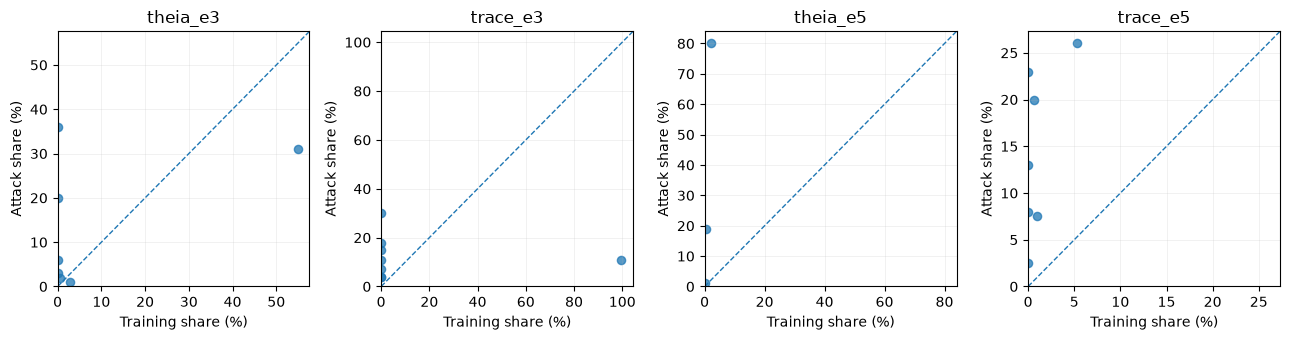

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Input
# ---------------------------------------------------------
FILE = "process_attack_training.csv"

df = pd.read_csv(FILE)

# ---------------------------------------------------------
# Process-level attack share
# ---------------------------------------------------------
df["attack_share"] = (
    df["attack_count"]
    / df.groupby("dataset")["attack_count"].transform("sum")
    * 100
)

# training_share is already percentage
df["training_share"] = pd.to_numeric(
    df["training_share"],
    errors="coerce"
)

# ---------------------------------------------------------
# Keep processes that appear in either distribution
# ---------------------------------------------------------
df = df[
    (df["attack_count"] > 0) |
    (df["training_share"] > 0)
].copy()

# ---------------------------------------------------------
# Plot
# ---------------------------------------------------------
datasets = list(df["dataset"].unique())

fig, axes = plt.subplots(
    1,
    len(datasets),
    figsize=(13, 3.5),
    sharex=False,
    sharey=False
)

if len(datasets) == 1:
    axes = [axes]

for ax, dataset in zip(axes, datasets):

    g = df[df["dataset"] == dataset].copy()

    # diagonal y = x
    max_value = max(
        g["training_share"].max(),
        g["attack_share"].max()
    )

    max_value = max_value * 1.05

    ax.plot(
        [0, max_value],
        [0, max_value],
        linestyle="--",
        linewidth=1
    )

    ax.scatter(
        g["training_share"],
        g["attack_share"],
        s=35,
        alpha=0.75
    )

    ax.set_title(dataset)

    ax.set_xlabel("Training share (%)")
    ax.set_ylabel("Attack share (%)")

    ax.set_xlim(0, max_value)
    ax.set_ylim(0, max_value)

    ax.grid(
        alpha=0.20,
        linewidth=0.6
    )



plt.tight_layout()

plt.savefig(
    "./process_result/figure2_training_vs_attack_process_share.pdf",
    bbox_inches="tight"
)

plt.savefig(
    "./process_result/figure2_training_vs_attack_process_share.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

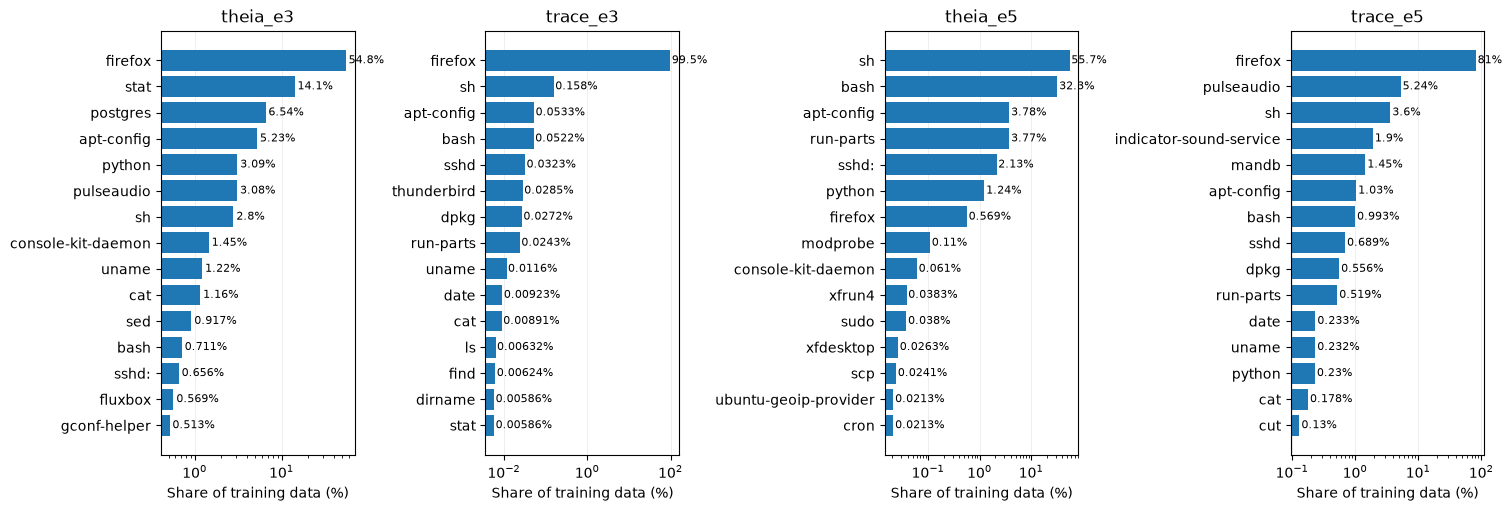

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Input
# ---------------------------------------------------------
FILE = "process_training.csv"

df = pd.read_csv(FILE)

# Make sure training share is numeric
df["training_share"] = pd.to_numeric(
    df["training_share"],
    errors="coerce"
)

df = df.dropna(
    subset=["training_share"]
).copy()

# Keep process-level observations only
df = df[df["training_share"] > 0].copy()

# ---------------------------------------------------------
# Plot settings
# ---------------------------------------------------------
datasets = list(df["dataset"].unique())

fig, axes = plt.subplots(
    1,
    len(datasets),
    figsize=(15, 5),
    constrained_layout=True
)

if len(datasets) == 1:
    axes = [axes]

for ax, dataset in zip(axes, datasets):

    g = (
        df[df["dataset"] == dataset]
        .sort_values("training_share", ascending=False)
        .head(15)
        .copy()
    )

    # Reverse order so the largest appears at the top
    g = g.iloc[::-1]

    ax.barh(
        g["process"],
        g["training_share"]
    )

    # Log scale makes the long tail visible
    ax.set_xscale("log")

    ax.set_title(dataset)

    ax.set_xlabel("Share of training data (%)")

    # Add value labels
    for y, value in enumerate(g["training_share"]):
        ax.text(
            value * 1.08,
            y,
            f"{value:.3g}%",
            va="center",
            fontsize=8
        )

    ax.grid(
        axis="x",
        alpha=0.25,
        linewidth=0.6
    )

    ax.set_axisbelow(True)



plt.savefig(
    "./process_result/figure1_training_process_representation.pdf",
    bbox_inches="tight"
)

plt.savefig(
    "./process_result/figure1_training_process_representation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Loading Nodes ...
[WindowsPath('process_result/theia-e3/nodes/file_00000.parquet'), WindowsPath('process_result/theia-e3/nodes/netflow_00000.parquet'), WindowsPath('process_result/theia-e3/nodes/subject_00000.parquet')]
file_00000.parquet                246,074
netflow_00000.parquet              69,870
subject_00000.parquet              92,375
------------------------------------------
Loaded Nodes : 408,319
Loading Nodes ...
[WindowsPath('process_result/trace-e3/nodes/file_00000.parquet'), WindowsPath('process_result/trace-e3/nodes/netflow_00000.parquet'), WindowsPath('process_result/trace-e3/nodes/subject_00000.parquet'), WindowsPath('process_result/trace-e3/nodes/subject_00001.parquet'), WindowsPath('process_result/trace-e3/nodes/subject_00002.parquet'), WindowsPath('process_result/trace-e3/nodes/subject_00003.parquet'), WindowsPath('process_result/trace-e3/nodes/subject_00004.parquet'), WindowsPath('process_result/trace-e3/nodes/subject_00005.parquet'), WindowsPath('process_result/

C:\Users\Asus\AppData\Local\Temp\ipykernel_1948\1973960247.py:280: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


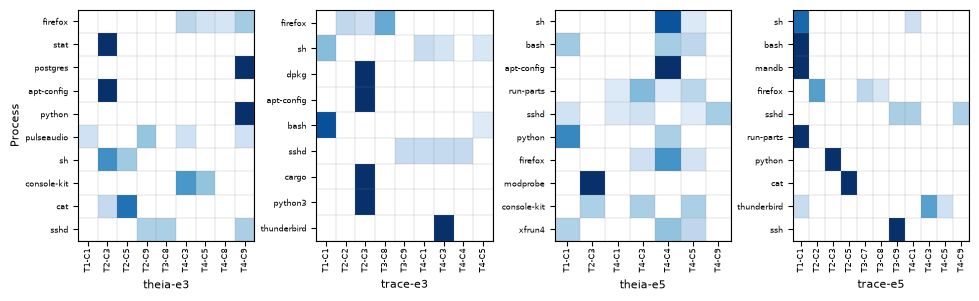

In [1]:

import numpy as np

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from df_generate import prepare_df


# =========================================================
# Settings
# =========================================================

PROCESS_COL = "cmdline_clean"
TOPOLOGY_COL = "topology_label"
COMMUNICATION_COL = "communication_label"



# ---------------------------------------------------------
# Fixed semantic ordering
# ---------------------------------------------------------


TOPOLOGY_CODES = {
    "process_centric": "T1",
    "file_centric": "T2",
    "socket_centric": "T3",
    "balanced_connector": "T4",
}

COMMUNICATION_CODES = {
    "spawner": "C1",
    "modifier": "C2",
    "read_dominant": "C3",
    "write_dominant": "C4",
    "read_write": "C5",
    "send_dominant": "C6",
    "receive_dominant": "C7",
    "bidirectional": "C8",
    "mixed_communication": "C9",
}



datasets = [
    "theia-e3",
    "trace-e3",
    "theia-e5",
    "trace-e5",

]
def plot_behavioral_profile(ax, dataset_name ,plot_df):

    # -----------------------------------------------------
    # Prepare data
    # -----------------------------------------------------

    plot_df["T_code"] = plot_df[TOPOLOGY_COL].map(
        TOPOLOGY_CODES
    )

    plot_df["C_code"] = plot_df[COMMUNICATION_COL].map(
        COMMUNICATION_CODES
    )

    plot_df = plot_df.dropna(
        subset=["T_code", "C_code"]
    ).copy()

    plot_df["profile"] = (
        plot_df["T_code"]
        + "-"
        + plot_df["C_code"]
    )

    # -----------------------------------------------------
    # Calculate profile share
    # -----------------------------------------------------
    profile_counts = (
        plot_df
        .groupby([PROCESS_COL, "profile"])
        .size()
        .rename("count")
        .reset_index()
    )

    profile_counts["total"] = (
        profile_counts
        .groupby(PROCESS_COL)["count"]
        .transform("sum")
    )

    profile_counts["share"] = (
        profile_counts["count"]
        / profile_counts["total"]
    )



    # -----------------------------------------------------
    # Matrix
    # -----------------------------------------------------
    matrix = (
        profile_counts
        .pivot(
            index=PROCESS_COL,
            columns="profile",
            values="share"
        )
    )

    # -----------------------------------------------------
    # Sort profiles
    # -----------------------------------------------------
    def profile_sort_key(profile):
        t, c = profile.split("-")
        return (
            int(t.replace("T", "")),
            int(c.replace("C", ""))
        )

    ordered_profiles = sorted(
        matrix.columns,
        key=profile_sort_key
    )

    matrix = matrix.reindex(
        columns=ordered_profiles
    )

# -----------------------------------------------------
# Sort processes by total number of samples
# -----------------------------------------------------
    process_totals = (
        profile_counts
        .groupby(PROCESS_COL)["count"]
        .sum()
    )

    matrix["_total_count"] = (
        matrix.index.map(process_totals)
    )

    matrix = (
        matrix
        .sort_values(
            "_total_count",
            ascending=False
        )
        .drop(columns="_total_count")
    )

    # -----------------------------------------------------
    # Plot
    # -----------------------------------------------------
    cmap = plt.cm.Blues.copy()
    cmap.set_bad(color="white")

    norm = Normalize(
        vmin=0,
        vmax=1.0
    )

    data = matrix.values.astype(float)

    ax.imshow(
        data,
        aspect="auto",
        interpolation="none",
        cmap=cmap,
        norm=norm
    )

    # -----------------------------------------------------
    # Profile labels BELOW the squares
    # -----------------------------------------------------
    ax.set_xticks(
        range(len(matrix.columns))
    )

    ax.set_xticklabels(
        matrix.columns,
        rotation=90,
        fontsize=5.5
    )

    ax.tick_params(
        axis="x",
        which="major",
        pad=2
    )

    # -----------------------------------------------------
    # Grid = square boundaries
    # -----------------------------------------------------
    ax.set_xticks(
        np.arange(-0.5, len(matrix.columns), 1),
        minor=True
    )

    ax.set_yticks(
        np.arange(-0.5, len(matrix.index), 1),
        minor=True
    )

    ax.grid(
        which="minor",
        color="gray",
        linewidth=0.35,
        alpha=0.45
    )

    ax.tick_params(
        which="minor",
        bottom=False,
        left=False
    )

    # -----------------------------------------------------
    # Process names
    # -----------------------------------------------------
    ax.set_yticks(
        range(len(matrix.index))
    )

    process_labels = []

    for process in matrix.index:
        parts = str(process).split("-")
        process_labels.append(
        "-".join(parts[:2])
        )

    ax.set_yticklabels(
        process_labels,
        fontsize=6
    )

    # -----------------------------------------------------
    # Dataset name
    # -----------------------------------------------------
    ax.set_xlabel(
        dataset_name,
        fontsize=8,
        labelpad=5
    )

    ax.set_ylabel("")



plot_dfs = {}
for x in datasets:
    plot_dfs[x] = prepare_df(x)




fig, axes = plt.subplots(
    1,
    4,
    figsize=(11.5, 3.0),
    gridspec_kw={
        "wspace": 0.35
    }
)

for ax, dataset in zip(axes, datasets):
    plot_behavioral_profile(
        ax,
        dataset,
        plot_dfs[dataset]
    )

axes[0].set_ylabel(
    "Process",
    fontsize=8,
    labelpad=3
)

plt.tight_layout()

plt.savefig(
    "./process_result/figure3_process_behavioral_profiles.pdf",
    bbox_inches="tight"
)

plt.savefig(
    "./process_result/figure3_process_behavioral_profiles.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()